In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

In [4]:
df = pd.read_csv('/content/diabetes.csv')

df.head()

,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,NaN,NaN,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,NaN,NaN,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,185.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,NaN,NaN,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,NaN,NaN,44.0,41.0,300.0


In [5]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Rows and Columns: (403, 19)

Column Names:
['id', 'chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'location', 'age', 'gender', 'height', 'weight', 'frame', 'bp.1s', 'bp.1d', 'bp.2s', 'bp.2d', 'waist', 'hip', 'time.ppn']


In [6]:
df.head()

,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,NaN,NaN,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,NaN,NaN,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,185.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,NaN,NaN,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,NaN,NaN,44.0,41.0,300.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        403 non-null    int64  
 1   chol      402 non-null    float64
 2   stab.glu  403 non-null    int64  
 3   hdl       402 non-null    float64
 4   ratio     402 non-null    float64
 5   glyhb     390 non-null    float64
 6   location  403 non-null    object 
 7   age       403 non-null    int64  
 8   gender    403 non-null    object 
 9   height    398 non-null    float64
 10  weight    402 non-null    float64
 11  frame     391 non-null    object 
 12  bp.1s     398 non-null    float64
 13  bp.1d     398 non-null    float64
 14  bp.2s     141 non-null    float64
 15  bp.2d     141 non-null    float64
 16  waist     401 non-null    float64
 17  hip       401 non-null    float64
 18  time.ppn  400 non-null    float64
dtypes: float64(13), int64(3), object(3)
memory usage: 59.9+ KB


In [8]:
df.isnull().sum()

,0
id,0
chol,1
stab.glu,0
hdl,1
ratio,1
glyhb,13
location,0
age,0
gender,0
height,5


In [9]:
df.describe()

,id,chol,stab.glu,hdl,ratio,glyhb,age,height,weight,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
count,403.000000,402.000000,403.000000,402.000000,402.000000,390.000000,403.000000,398.000000,402.000000,398.000000,398.000000,141.000000,141.000000,401.000000,401.000000,400.000000
mean,15978.310174,207.845771,106.672457,50.445274,4.521642,5.589769,46.851117,66.020101,177.592040,136.904523,83.321608,152.382979,92.524823,37.900249,43.039900,341.250000
std,11881.122124,44.445557,53.076655,17.262626,1.727886,2.242595,16.312333,3.918515,40.340666,22.741033,13.589227,21.712952,11.555198,5.729313,5.656713,309.540953
min,1000.000000,78.000000,48.000000,12.000000,1.500000,2.680000,19.000000,52.000000,99.000000,90.000000,48.000000,110.000000,60.000000,26.000000,30.000000,5.000000
25%,4792.500000,179.000000,81.000000,38.000000,3.200000,4.380000,34.000000,63.000000,151.000000,121.250000,75.000000,138.000000,84.000000,33.000000,39.000000,90.000000
50%,15766.000000,204.000000,89.000000,46.000000,4.200000,4.840000,45.000000,66.000000,172.500000,136.000000,82.000000,149.000000,92.000000,37.000000,42.000000,240.000000
75%,20336.000000,230.000000,106.000000,59.000000,5.400000,5.600000,60.000000,69.000000,200.000000,146.750000,90.000000,161.000000,100.000000,41.000000,46.000000,517.500000
max,41756.000000,443.000000,385.000000,120.000000,19.299999,16.110001,92.000000,76.000000,325.000000,250.000000,124.000000,238.000000,124.000000,56.000000,64.000000,1560.000000


In [10]:
print(df['glyhb'].describe())

count    390.000000
mean       5.589769
std        2.242595
min        2.680000
25%        4.380000
50%        4.840000
75%        5.600000
max       16.110001
Name: glyhb, dtype: float64


In [11]:
print("Missing glyhb values:", df['glyhb'].isnull().sum())

Missing glyhb values: 13


In [12]:
df = df.dropna(subset=['glyhb']).copy()

print("New dataset shape:", df.shape)

New dataset shape: (390, 19)


In [13]:
df['Outcome'] = (df['glyhb'] >= 6.5).astype(int)

In [14]:
df[['glyhb', 'Outcome']].head(10)

,glyhb,Outcome
0,4.31,0
1,4.44,0
2,4.64,0
3,4.63,0
4,7.72,1
5,4.81,0
6,4.84,0
7,3.94,0
8,4.84,0
9,5.78,0


In [16]:
print(df['Outcome'].value_counts())

Outcome
0    325
1     65
Name: count, dtype: int64


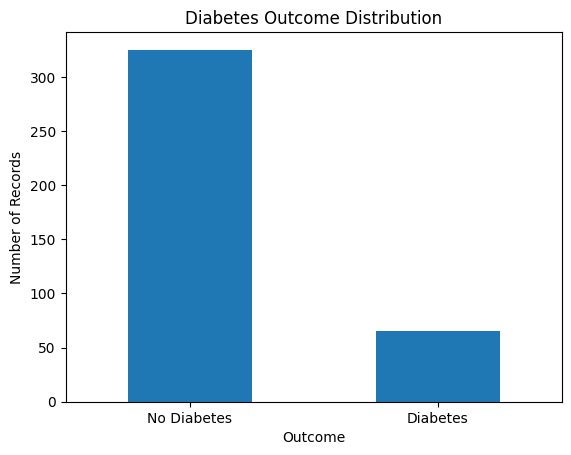

In [17]:
df['Outcome'].value_counts().plot(kind='bar')

plt.xlabel('Outcome')
plt.ylabel('Number of Records')
plt.title('Diabetes Outcome Distribution')
plt.xticks([0, 1], ['No Diabetes', 'Diabetes'], rotation=0)

plt.show()

In [18]:
X = df.drop(['Outcome', 'glyhb', 'id'], axis=1)

y = df['Outcome']

In [19]:
print("Features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['chol', 'stab.glu', 'hdl', 'ratio', 'location', 'age', 'gender', 'height', 'weight', 'frame', 'bp.1s', 'bp.1d', 'bp.2s', 'bp.2d', 'waist', 'hip', 'time.ppn']

X shape: (390, 17)
y shape: (390,)


In [20]:
print(X.dtypes)

chol        float64
stab.glu      int64
hdl         float64
ratio       float64
location     object
age           int64
gender       object
height      float64
weight      float64
frame        object
bp.1s       float64
bp.1d       float64
bp.2s       float64
bp.2d       float64
waist       float64
hip         float64
time.ppn    float64
dtype: object


In [21]:
X = pd.get_dummies(X, columns=['location', 'gender', 'frame'], drop_first=True)

In [22]:
print(X.head())
print(X.dtypes)

    chol  stab.glu   hdl  ratio  age  height  weight  bp.1s  bp.1d  bp.2s  \
0  203.0        82  56.0    3.6   46    62.0   121.0  118.0   59.0    NaN   
1  165.0        97  24.0    6.9   29    64.0   218.0  112.0   68.0    NaN   
2  228.0        92  37.0    6.2   58    61.0   256.0  190.0   92.0  185.0   
3   78.0        93  12.0    6.5   67    67.0   119.0  110.0   50.0    NaN   
4  249.0        90  28.0    8.9   64    68.0   183.0  138.0   80.0    NaN   

   bp.2d  waist   hip  time.ppn  location_Louisa  gender_male  frame_medium  \
0    NaN   29.0  38.0     720.0            False        False          True   
1    NaN   46.0  48.0     360.0            False        False         False   
2   92.0   49.0  57.0     180.0            False        False         False   
3    NaN   33.0  38.0     480.0            False         True         False   
4    NaN   44.0  41.0     300.0            False         True          True   

   frame_small  
0        False  
1        False  
2        Fa

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [24]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (312, 18)
Testing data: (78, 18)


In [25]:
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)

X_test_scaled = scaler.transform(X_test_imputed)

In [27]:
model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

In [28]:
model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [29]:
y_pred = model.predict(X_test_scaled)

In [30]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [31]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))

Accuracy: 0.846


In [32]:
precision = precision_score(y_test, y_pred)

print("Precision:", round(precision, 3))

Precision: 0.524


In [33]:
recall = recall_score(y_test, y_pred)

print("Recall:", round(recall, 3))

Recall: 0.846


In [34]:
f1 = f1_score(y_test, y_pred)

print("F1-score:", round(f1, 3))

F1-score: 0.647


In [35]:
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", round(roc_auc, 3))

ROC-AUC: 0.925


In [36]:
print("===== MODEL EVALUATION =====")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1-score :", round(f1, 3))
print("ROC-AUC  :", round(roc_auc, 3))

===== MODEL EVALUATION =====
Accuracy : 0.846
Precision: 0.524
Recall   : 0.846
F1-score : 0.647
ROC-AUC  : 0.925


In [37]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Diabetes', 'Diabetes']
))

              precision    recall  f1-score   support

 No Diabetes       0.96      0.85      0.90        65
    Diabetes       0.52      0.85      0.65        13

    accuracy                           0.85        78
   macro avg       0.74      0.85      0.77        78
weighted avg       0.89      0.85      0.86        78



In [38]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[55 10]
 [ 2 11]]


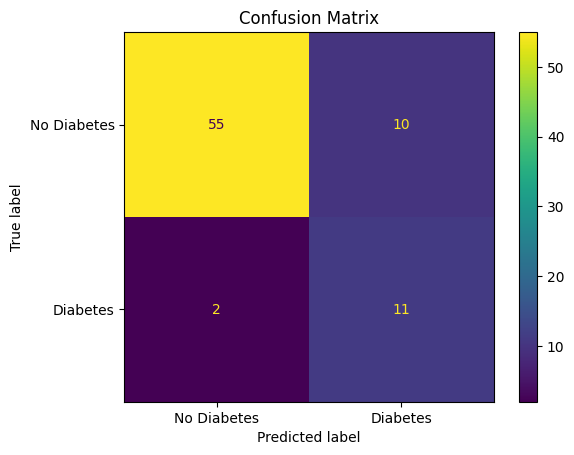

In [39]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Diabetes', 'Diabetes']
)

disp.plot()

plt.title('Confusion Matrix')
plt.show()

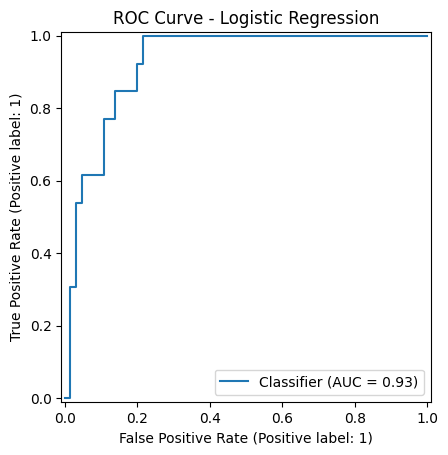

In [40]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title('ROC Curve - Logistic Regression')
plt.show()

In [41]:
feature_names = X.columns

In [42]:
coefficients = model.coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

coef_df

,Feature,Coefficient
1,stab.glu,1.973490
11,waist,0.738609
4,age,0.680138
7,bp.1s,0.489024
0,chol,0.425886
17,frame_small,0.280191
15,gender_male,0.253027
13,time.ppn,0.172599
16,frame_medium,0.103831
8,bp.1d,0.037709


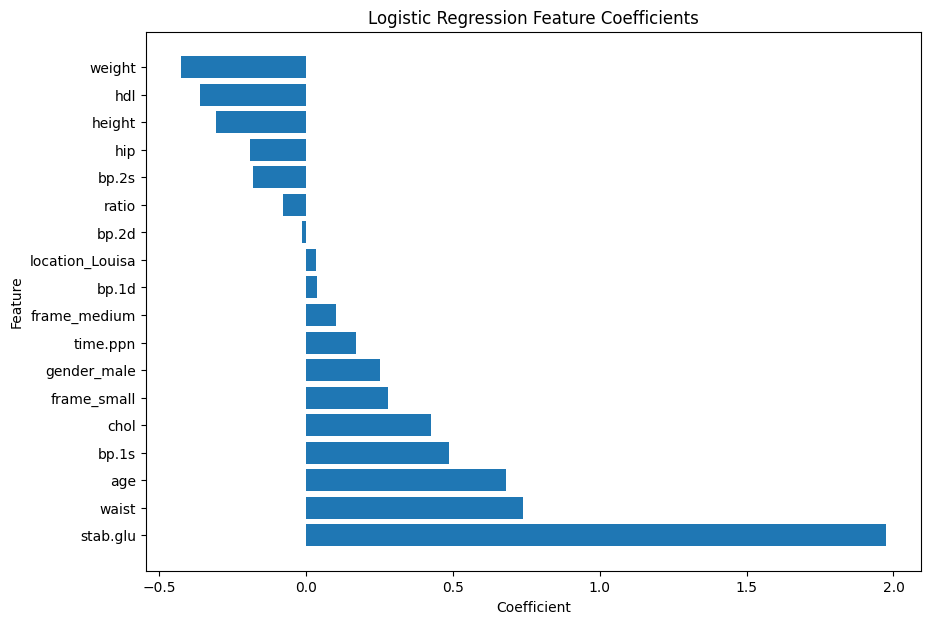

In [43]:
plt.figure(figsize=(10, 7))

plt.barh(
    coef_df['Feature'],
    coef_df['Coefficient']
)

plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.title('Logistic Regression Feature Coefficients')

plt.show()

In [44]:
print("Strongest positive coefficients:")
print(
    coef_df
    .sort_values('Coefficient', ascending=False)
    .head(5)
)

Strongest positive coefficients:
     Feature  Coefficient
1   stab.glu     1.973490
11     waist     0.738609
4        age     0.680138
7      bp.1s     0.489024
0       chol     0.425886


In [45]:
print("Strongest negative coefficients:")
print(
    coef_df
    .sort_values('Coefficient', ascending=True)
    .head(5)
)

Strongest negative coefficients:
   Feature  Coefficient
6   weight    -0.424129
2      hdl    -0.359943
5   height    -0.306724
12     hip    -0.189686
9    bp.2s    -0.178748
